# Technical validation for the multi-device, multi-crop spectral dataset

This notebook produces every number, table and figure in the **Data Records** and **Technical Validation** sections of the paper.

1. Loads the three devices and attach leaf-level ground truth (expert score and laboratory value)
2. Data checks: duplicate removal, label validity, week coverage, ground-truth coverage
3. CI-710 calibration check
4. Sample-count audit and `metadata.csv`
5. Mean spectrum per class
6. Ground-truth validation
All outputs are written to `paper_outputs/`. Run the cells top to bottom.

## 0. Setup

In [1]:
import os
import re
import ast
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from buaiir_spectra.data.dataset import *          # SpectralDataset, SpectralDataLoader, Device
from buaiir_spectra.data.dataset import L_Device

warnings.filterwarnings(action="ignore")

plt.rcParams.update({
    'figure.figsize': (10, 7),
    'font.size': 15,
    'axes.titlesize': 17,
    'axes.labelsize': 17,
    'xtick.labelsize': 15,
    'ytick.labelsize': 15,
    'legend.fontsize': 15,
    'figure.titlesize': 20,
})

## Settings

In [2]:
#!pip install buaiir-spectra
#!unzip spectra_data.zip

In [3]:
DATA_ROOT = pathlib.Path('spectra_data')
LAB_FILE = DATA_ROOT / 'laboratory_data.xlsx'
OUT_DIR = pathlib.Path('paper_outputs')
OUT_DIR.mkdir(exist_ok=True)

CLASS_CODES = ['HLT', 'BLB', 'BRD', 'MLN', 'MSV', 'CBSD', 'CBB']
CROP_FULL_NAMES = {'B': 'Beans', 'M': 'Maize', 'C': 'Cassava'}
CROP_CLASSES = {'B': ['HLT', 'BLB', 'BRD'], 'M': ['HLT', 'MLN', 'MSV'], 'C': ['HLT', 'CBSD', 'CBB']}
DEVICE_DISPLAY_NAMES = {Device.BIO_SCIENCE: "CI-710", Device.SCAN_CORDER: "ScanCorder", Device.LOW_COST: "Low-Cost"}


CLASS_COLOR_MAP = {'HLT': '#009E73', 'BLB': '#D55E00', 'MLN': '#D55E00', 'CBSD': '#D55E00',
                   'BRD': '#0072B2', 'MSV': '#0072B2', 'CBB': '#0072B2'}
CLASS_LINESTYLE = {'HLT': '-', 'BLB': '--', 'MLN': '--', 'CBSD': '--', 'BRD': '-.', 'MSV': '-.', 'CBB': '-.'}
#CLASS_COLOR_MAP = {'HLT': 'green', 'BLB': 'tab:orange', 'BRD': 'tab:blue', 'MLN': 'tab:purple',
                   #'MSV': 'tab:brown', 'CBSD': 'tab:pink', 'CBB': 'tab:gray'}

# Collection week in which each crop was inoculated (Section 2.1).
INOCULATION_WEEK = {'B': 2, 'M': 3, 'C': 3}

# Preprocessing that the manuscript describes (Section 4.2.1). Change the text if you change these.
OUTLIER_BOUNDS = {Device.SCAN_CORDER: (-0.5, 2.0)}
DEVICE_WAVELENGTH_BOUNDS = {Device.BIO_SCIENCE: (400, 950)}

LAB_CLASS_ALIASES = {'CMD': 'CBSD'}

# CONFIRM 2: Titer_1/Score_1 = leaf a (1), Titer_2/Score_2 = leaf b (2), third column = leaf c (3).
LAB_LEAF_COLUMNS = {1: ('Score_1', 'Titer_1'), 2: ('Score_2', 'Titer_2'), 3: ('Score_3', 'Titer_3')}

CI710_WEEK_OFFSET = {}

# Assay and unit of the laboratory value per class (Section 2.3, Table 5). Edit to match the lab.
LAB_ASSAY = {'BLB': 'ELISA', 'CBB': 'qPCR', 'BRD': 'BR-qPCR', 'MLN': 'RT-qPCR', 'MSV': 'qPCR', 'CBSD': 'RT-qPCR'}
LAB_UNIT = {'ELISA': 'Absorbance (OD)', 'BR-qPCR': 'Ct value', 'RT-qPCR': 'Ct value', 'qPCR': 'Ct value'}
# Unit of the healthy-control lab values per crop. A healthy line is drawn next to a disease only
# when the units match (beans controls were measured by ELISA, so they are not shown next to BRD Ct).
HLT_UNIT = {'B': 'Absorbance (OD)', 'M': 'Ct value', 'C': 'Ct value'}
INVERT_CT_AXIS = True

CT_CUTOFF_BY_CROP = {'B': 35.0, 'M': 35.0, 'C': 35.0}
LAB_CUTOFF = {'Absorbance (OD)': 0.5}   # set when the lab confirms the ELISA rule


def lab_cutoff(crop, unit):
    """Positivity cut-off for a crop and unit (None if not set)."""
    if 'Ct' in unit:
        return CT_CUTOFF_BY_CROP.get(crop)
    return LAB_CUTOFF.get(unit)


## Low-Cost loading patch (run before loading)

The Low-Cost spectra are already max-normalized on the device, so the package's experimental linearization step is skipped. The patch also records which of the two measurement points each spectrum came from.

In [4]:
@staticmethod
def _load_without_linearization(val):
    x_f = pd.read_csv(val['Files'])
    image_f = val['Images']
    y_f = val.drop(['Files', 'Images'])

    spec_1 = ast.literal_eval(x_f.loc[:, 'spectral_1'][0])
    spec_2 = ast.literal_eval(x_f.loc[:, 'spectral_2'][0])
    if isinstance(spec_1, dict):
        spec_1, spec_2 = spec_1['intensity'], spec_2['intensity']

    x = np.vstack([np.array(spec_1, dtype=np.float32)[None, :],
                   np.array(spec_2, dtype=np.float32)[None, :]])
    y = pd.DataFrame(data=[y_f.values, y_f.values], columns=y_f.index.to_list())
    y['Point'] = ['1', '2']

    img = Image.open(image_f).resize((244, 244), resample=Image.Resampling.LANCZOS)
    img = np.asarray(img)[None, :]
    img = np.vstack([img, img])
    return x, img, y

L_Device.load = _load_without_linearization
print("Patched L_Device.load.")

Patched L_Device.load.


## 1. Load the spectra and attach leaf-level ground truth

The package joins the laboratory sheet per **plant**, so every reading receives all three leaves' values. The earlier version of this notebook then kept `Titer_1` and `Score_1` for every reading, which gave leaves b and c the values of leaf a. Here each reading is matched to its **own leaf**.

In [5]:
def parse_identifiers(y, device):
    # Crop, class, week, plant, leaf and point for every reading, from the package output.
    meta = pd.DataFrame({
        'device': DEVICE_DISPLAY_NAMES[device],
        'crop': y['Crop'].astype(str).values,
        'class': y['Class'].astype(str).values,
        'week': pd.to_numeric(y['Week']).astype(int).values,
        'label': y['Label'].astype(str).values,
        'R': y['R'].astype(str).values,
    })
    meta['plant'] = pd.to_numeric(meta['label'].str.extract(r'(\d+)$')[0], errors='coerce')
    R = meta['R']
    if device == Device.SCAN_CORDER:          # e.g. 'Rb1g': leaf b, point g
        meta['leaf'] = R.str[1].map({'a': 1, 'b': 2, 'c': 3})
        meta['point'] = R.str[-1]
    elif device == Device.BIO_SCIENCE:        # e.g. 'Ra2b': leaf 2, point b
        meta['leaf'] = pd.to_numeric(R.str.extract(r'^Ra(\d+)')[0], errors='coerce')
        meta['point'] = R.str[-1]
    else:                                     # Low-Cost: 'R2' = leaf 2 (folder "Reading 2")
        meta['leaf'] = pd.to_numeric(R.str.extract(r'^R(\d+)')[0], errors='coerce')
        meta['point'] = y['Point'].astype(str).values
    if device == Device.BIO_SCIENCE and CI710_WEEK_OFFSET:
        meta['week'] = meta['week'] + meta['class'].map(CI710_WEEK_OFFSET).fillna(0).astype(int)
    return meta


def load_spectral(device):
    ds = SpectralDataset(DATA_ROOT, device=device)
    loader = SpectralDataLoader(ds, batch_size=len(ds), shuffle=False)
    x, img, y = next(iter(loader))
    y = y.reset_index(drop=True)
    meta = parse_identifiers(y, device)
    return np.asarray(x, dtype=np.float32), meta, np.asarray(ds.wavelength, dtype=float), ds


def load_lab_table(path=LAB_FILE):
    # One row per leaf and week: expert score and laboratory value.
    lab = pd.read_excel(path)
    if 'Titer_2.1' in lab.columns:                       # third titre column is mislabelled "Titer_2"
        lab = lab.rename(columns={'Titer_2.1': 'Titer_3'})
        same = (lab['Titer_2'] == lab['Titer_3']).sum()
        print(f"Lab sheet: third titre column renamed Titer_3. "
              f"{same} rows have identical Titer_2 and Titer_3 values - check these for copy errors.")
    lab['Class'] = lab['Class'].astype(str).replace(LAB_CLASS_ALIASES)
    parts = []
    for leaf, (score_col, titre_col) in LAB_LEAF_COLUMNS.items():
        part = lab[['Week', 'Crop', 'Class', 'Plant_No']].copy()
        part.columns = ['week', 'crop', 'class', 'plant']
        part['leaf'] = leaf
        part['expert_score'] = lab[score_col].values
        part['lab_value'] = lab[titre_col].values
        parts.append(part)
    leaf_df = pd.concat(parts, ignore_index=True)
    leaf_df['crop'] = leaf_df['crop'].astype(str)
    dup = leaf_df.duplicated(['week', 'crop', 'class', 'plant', 'leaf']).sum()
    if dup:
        print(f"!! {dup} duplicated leaf-weeks in the lab sheet; keeping the first of each.")
        leaf_df = leaf_df.drop_duplicates(['week', 'crop', 'class', 'plant', 'leaf'])
    return leaf_df


def attach_ground_truth(meta, lab_leaf):
    keys = ['week', 'crop', 'class', 'plant', 'leaf']
    out = meta.merge(lab_leaf, how='left', on=keys, validate='many_to_one')
    assert len(out) == len(meta)
    out['lab_assay'] = out['class'].map(LAB_ASSAY)
    inoc = out['crop'].map(INOCULATION_WEEK)
    out['inoculated'] = ((out['class'] != 'HLT') & (out['week'] >= inoc)).astype(int)
    return out


lab_leaf = load_lab_table()
global_state = {}
for device in Device.get_devices():
    print(f"Loading {device.name} ...")
    x, meta, wl, ds = load_spectral(device)
    meta = attach_ground_truth(meta, lab_leaf)
    global_state[device] = {'x': x, 'meta': meta, 'wavelength': wl, 'ds': ds, 'n_loaded': len(meta)}
    print(f"  {len(meta)} readings, {len(wl)} bands, classes: {sorted(meta['class'].unique())}")

Loading BIO_SCIENCE ...
  3783 readings, 3648 bands, classes: ['BLB', 'BRD', 'CBB', 'CBSD', 'HLT', 'MLN', 'MSV']
Loading SCAN_CORDER ...
  4091 readings, 12 bands, classes: ['BLB', 'BRD', 'CBB', 'CBSD', 'HLT', 'MLN', 'MSV']
Loading LOW_COST ...
  3690 readings, 381 bands, classes: ['BLB', 'BRD', 'CBB', 'CBSD', 'HLT', 'MLN', 'MSV']


## 2. Data checks

In [6]:
dup_report = []
for device, st in global_state.items():
    meta, x = st['meta'].reset_index(drop=True), st['x']
    key = pd.concat([meta[['crop', 'class', 'week', 'plant', 'leaf', 'point', 'R']],
                     pd.DataFrame(x).round(6)], axis=1)
    is_dup = key.duplicated(keep='first').values
    for cls, n in meta.loc[is_dup, 'class'].value_counts().items():
        dup_report.append({'device': DEVICE_DISPLAY_NAMES[device], 'class': cls, 'duplicates_removed': n})
    st['x'], st['meta'] = x[~is_dup], meta.loc[~is_dup].reset_index(drop=True)
    st['n_duplicates'] = int(is_dup.sum())
    print(f"{DEVICE_DISPLAY_NAMES[device]}: removed {is_dup.sum()} exact duplicates, {len(st['meta'])} readings remain")

N_DUPLICATES_TOTAL = sum(st['n_duplicates'] for st in global_state.values())
print(f"\nTotal duplicates removed (the [N] in Section 4.1): {N_DUPLICATES_TOTAL}")
pd.DataFrame(dup_report).to_csv(OUT_DIR / 'duplicates_removed.csv', index=False)

CI-710: removed 0 exact duplicates, 3783 readings remain
ScanCorder: removed 0 exact duplicates, 4091 readings remain
Low-Cost: removed 0 exact duplicates, 3690 readings remain

Total duplicates removed (the [N] in Section 4.1): 0


### 2b. Label validity
Every reading should have a known crop and class, a class that belongs to its crop, plant 1-5 and leaf 1-3. Anything listed here should be fixed in the raw files before release.

In [7]:
bad_rows = []
for device, st in global_state.items():
    m = st['meta']
    problems = pd.Series('', index=m.index)
    problems[~m['class'].isin(CLASS_CODES)] += 'unknown class; '
    problems[[c not in CROP_CLASSES.get(cr, []) for cr, c in zip(m['crop'], m['class'])]] += 'class not in crop; '
    problems[~m['plant'].isin([1, 2, 3, 4, 5])] += 'plant not 1-5; '
    problems[~m['leaf'].isin([1, 2, 3])] += 'leaf not 1-3; '
    bad = m[problems != ''].assign(problem=problems[problems != ''])
    bad_rows.append(bad)
    print(f"{DEVICE_DISPLAY_NAMES[device]}: {len(bad)} readings with label problems")
bad_labels = pd.concat(bad_rows, ignore_index=True)
bad_labels.to_csv(OUT_DIR / 'label_problems.csv', index=False)
bad_labels.groupby(['device', 'problem', 'label']).size().rename('readings').reset_index().head(40)

CI-710: 93 readings with label problems
ScanCorder: 0 readings with label problems
Low-Cost: 0 readings with label problems


,device,problem,label,readings
0,CI-710,leaf not 1-3;,BBLB5,1
1,CI-710,leaf not 1-3;,BBRD1,3
2,CI-710,leaf not 1-3;,BBRD3,2
3,CI-710,leaf not 1-3;,BBRD4,3
4,CI-710,leaf not 1-3;,BBRD5,1
5,CI-710,leaf not 1-3;,BHLT1,1
6,CI-710,leaf not 1-3;,BHLT5,2
7,CI-710,leaf not 1-3;,CCBB1,1
8,CI-710,leaf not 1-3;,CCBB2,4
9,CI-710,leaf not 1-3;,CCBB3,2


### 2c. Week coverage per device
Each class should cover weeks 1-11 (beans) or 1-15 (maize, cassava) on **every** device. If the CI-710 shows fewer weeks for inoculated classes than the other two devices, its week numbers are shifted - see CONFIRM 3 in the settings.

In [8]:
rows = []
for device, st in global_state.items():
    for (crop, cls), g in st['meta'].groupby(['crop', 'class']):
        w = sorted(g['week'].unique())
        rows.append({'crop': crop, 'class': cls, 'device': DEVICE_DISPLAY_NAMES[device],
                     'n_weeks': len(w), 'first': w[0], 'last': w[-1]})
weeks_df = pd.DataFrame(rows)
weeks_table = weeks_df.pivot_table(index=['crop', 'class'], columns='device', values='n_weeks')
weeks_table['all_devices_agree'] = weeks_table.nunique(axis=1) == 1
weeks_table

device      CI-710  Low-Cost  ScanCorder  all_devices_agree
crop class                                                 
B    BLB      11.0      11.0        11.0               True
     BRD      11.0      11.0        11.0               True
     HLT      11.0      11.0        11.0               True
C    CBB      15.0      15.0        15.0               True
     CBSD     15.0      15.0        15.0               True
     HLT      15.0      15.0        15.0               True
M    HLT      15.0      15.0        15.0               True
     MLN      15.0      15.0        15.0               True
     MSV      15.0      15.0        15.0               True

### 2d. Ground-truth coverage
Share of readings that received an expert score and a laboratory value. Low coverage for a whole class usually means a naming mismatch between the spectra and the lab sheet (for example CMD vs CBSD, or a plant number outside 1-5).

In [9]:
rows = []
for device, st in global_state.items():
    for (crop, cls), g in st['meta'].groupby(['crop', 'class']):
        rows.append({'device': DEVICE_DISPLAY_NAMES[device], 'crop': crop, 'class': cls, 'readings': len(g),
                     'with_score_%': round(100 * g['expert_score'].notna().mean(), 1),
                     'with_lab_value_%': round(100 * g['lab_value'].notna().mean(), 1)})
coverage = pd.DataFrame(rows)
coverage.to_csv(OUT_DIR / 'ground_truth_coverage.csv', index=False)
coverage

,device,crop,class,readings,with_score_%,with_lab_value_%
0,CI-710,B,BLB,331,99.7,99.7
1,CI-710,B,BRD,339,97.3,97.3
2,CI-710,B,HLT,333,99.1,99.1
3,CI-710,C,CBB,461,97.6,97.6
4,CI-710,C,CBSD,469,95.9,95.9
5,CI-710,C,HLT,458,98.3,98.3
6,CI-710,M,HLT,450,100.0,100.0
7,CI-710,M,MLN,475,94.7,94.7
8,CI-710,M,MSV,467,96.4,96.4
9,ScanCorder,B,BLB,365,100.0,100.0


## 3. CI-710 calibration check
Recomputes reflectance as 100 x (raw - dark) / (light - dark), clipped to 0-100 %, from each exported CI-710 file and compares it with the calibrated values the instrument stored.

In [10]:
def read_ci710_sections(path):
    # Spectrum (wavelength, raw, calibrated %) and references (wavelength, light, dark).
    lines = pathlib.Path(path).read_text(errors='ignore').splitlines()
    def block(header_start):
        i = next(k for k, l in enumerate(lines) if l.startswith(header_start)) + 1
        rows = []
        while i < len(lines) and lines[i].strip() and lines[i][0].isdigit():
            rows.append([float(v.replace('%', '')) for v in lines[i].split(',')[:3]])
            i += 1
        return np.array(rows)
    return block('Wavelength, Raw'), block('Wavelength, Light')


ds = global_state[Device.BIO_SCIENCE]['ds']
files = [f for fl in ds.final_df['Files'] for f in (fl if isinstance(fl, (list, tuple)) else [fl])]
max_diff, n_checked, n_failed, n_undefined = 0.0, 0, 0, 0
for f in files:
    try:
        spec, ref = read_ci710_sections(f)
        denom = ref[:, 1] - ref[:, 2]
        ok = denom != 0                    # light == dark at a few edge pixels: reflectance undefined
        n_undefined += int((~ok).sum())
        recomputed = np.clip(100 * (spec[ok, 1] - ref[ok, 2]) / denom[ok], 0, 100)
        max_diff = max(max_diff, float(np.max(np.abs(recomputed - spec[ok, 2]))))
        n_checked += 1
    except Exception as e:
        n_failed += 1
print(f"CI-710 files checked: {n_checked}, unreadable: {n_failed}")
print(f"Largest difference between recomputed and stored reflectance: {max_diff:.6f} percentage points")
print(f"Wavelength points skipped because light = dark (detector edges): {n_undefined}")

CI-710 files checked: 3783, unreadable: 0
Largest difference between recomputed and stored reflectance: 0.000000 percentage points
Wavelength points skipped because light = dark (detector edges): 974


## 4. Sample-count audit and metadata.csv
Counts are after duplicate removal. Ground-truth leaf-weeks come from the lab sheet (one score and one value per leaf per week), so they are the same for all devices.

In [11]:
order = [('B', 'HLT'), ('B', 'BLB'), ('B', 'BRD'), ('M', 'HLT'), ('M', 'MLN'), ('M', 'MSV'),
         ('C', 'HLT'), ('C', 'CBSD'), ('C', 'CBB')]
devices = Device.get_devices()
audit = []
for crop, cls in order:
    row = {'Crop': CROP_FULL_NAMES[crop], 'Class': cls}
    weeks = set()
    for device in devices:
        m = global_state[device]['meta']
        g = m[(m['crop'] == crop) & (m['class'] == cls)]
        row[DEVICE_DISPLAY_NAMES[device]] = len(g)
        weeks |= set(g['week'])
    row['Weeks'] = len(weeks)
    lw = lab_leaf[(lab_leaf['crop'] == crop) & (lab_leaf['class'] == cls)]
    row['Ground truth (leaf-weeks)'] = int((lw['expert_score'].notna() & lw['lab_value'].notna()).sum())
    audit.append(row)
audit = pd.DataFrame(audit)[['Crop', 'Class', 'Weeks', 'CI-710', 'ScanCorder', 'Low-Cost', 'Ground truth (leaf-weeks)']]
totals = audit[['CI-710', 'ScanCorder', 'Low-Cost', 'Ground truth (leaf-weeks)']].sum()
audit.to_csv(OUT_DIR / 'table6_sample_audit.csv', index=False)
print(audit.to_string(index=False))
TOTAL_READINGS = int(totals[['CI-710', 'ScanCorder', 'Low-Cost']].sum())

   Crop Class  Weeks  CI-710  ScanCorder  Low-Cost  Ground truth (leaf-weeks)
  Beans   HLT     11     333         394       330                        165
  Beans   BLB     11     331         365       330                        165
  Beans   BRD     11     339         370       330                        165
  Maize   HLT     15     450         495       450                        225
  Maize   MLN     15     475         492       450                        225
  Maize   MSV     15     467         487       450                        225
Cassava   HLT     15     458         504       450                        225
Cassava  CBSD     15     469         492       450                        225
Cassava   CBB     15     461         492       450                        225


In [12]:
metadata = pd.concat([st['meta'].copy() for st in global_state.values()], ignore_index=True)
metadata = metadata[['device','crop','class','plant','leaf','point','week','inoculated','expert_score','lab_value','lab_assay','label','R']]
metadata = metadata.rename(columns={'R': 'reading_code'})
metadata['crop'] = metadata['crop'].map(CROP_FULL_NAMES)
metadata['weeks_post_inoculation'] = np.where(metadata['class'] == 'HLT', np.nan, metadata['week'] - metadata['crop'].map({'Beans': 2, 'Maize': 3, 'Cassava': 3}))
metadata.loc[metadata['class'] == 'HLT', 'lab_assay'] = metadata.loc[metadata['class'] == 'HLT', 'crop'].map({'Beans': 'ELISA', 'Maize': 'qPCR-based', 'Cassava': 'qPCR-based'})
is_retake = (metadata['device'] == 'CI-710') & (metadata['leaf'] > 3)
metadata['ci710_retake_unassigned'] = is_retake.astype(int)
metadata.loc[is_retake, 'leaf'] = np.nan
metadata.insert(0, 'reading_id', range(1, len(metadata) + 1))
metadata.to_csv(OUT_DIR / 'metadata.csv', index=False)
print(f"Saved {len(metadata):,} rows -> {OUT_DIR / 'metadata.csv'}")

start = 0
for device, st in global_state.items():
    n = len(st['meta'])
    wl = np.round(np.asarray(st['ds'].wavelength, dtype=float), 2)
    spectra = pd.DataFrame(st['x'], columns=[f"{w:g}" for w in wl])
    spectra.insert(0, 'reading_id', metadata['reading_id'].iloc[start:start + n].values)
    name = f"spectra_{DEVICE_DISPLAY_NAMES[device]}.csv"
    spectra.to_csv(OUT_DIR / name, index=False, float_format='%.6g')
    print(f"Saved {n:,} spectra x {len(wl)} wavelengths -> {OUT_DIR / name}")
    start += n

Saved 11,564 rows -> paper_outputs0/metadata.csv
Saved 3,783 spectra x 3648 wavelengths -> paper_outputs0/spectra_CI-710.csv
Saved 4,091 spectra x 12 wavelengths -> paper_outputs0/spectra_ScanCorder.csv
Saved 3,690 spectra x 381 wavelengths -> paper_outputs0/spectra_Low-Cost.csv


## 5. Mean spectrum per class

ScanCorder outlier filter (-0.5, 2.0): removed 128 of 4091 readings (3.1%)  -> [N] and [X]% in Section 4.2.1
Saved -> paper_outputs0/mean_spectra.png


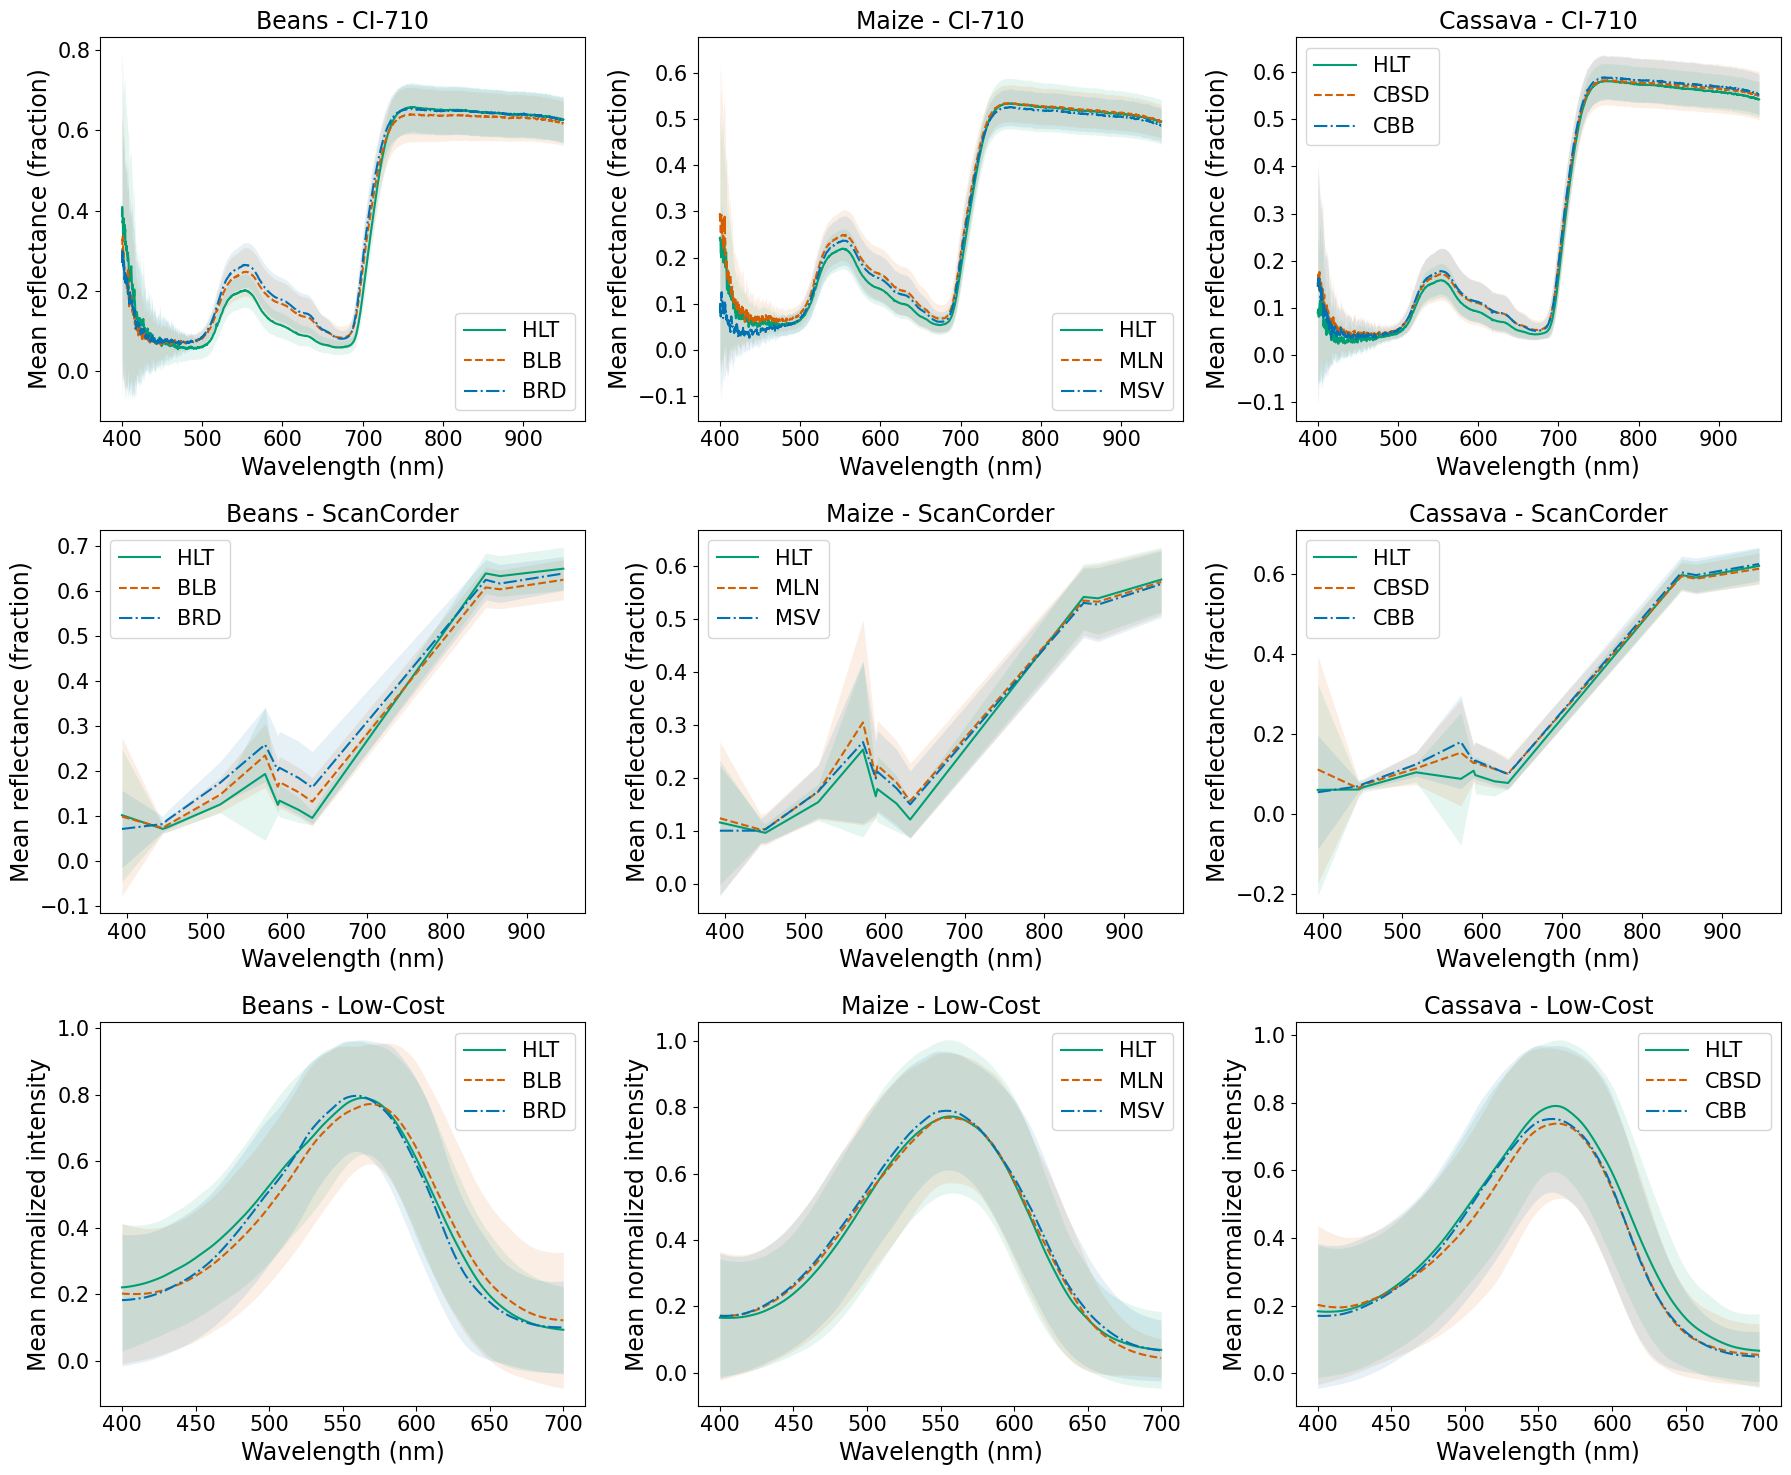

In [13]:
def outlier_mask(device, x):
    # True for readings kept: every value inside the device's bounds (if it has any).
    bounds = OUTLIER_BOUNDS.get(device)
    if bounds is None:
        return np.ones(len(x), dtype=bool)
    lo, hi = bounds
    return np.all((x >= lo) & (x <= hi), axis=1)


def trim_to_calibrated_range(device, x, wl):
    bounds = DEVICE_WAVELENGTH_BOUNDS.get(device)
    if bounds is None:
        return x, wl
    keep = (wl >= bounds[0]) & (wl <= bounds[1])
    return x[:, keep], wl[keep]


def prepared_spectra(device, report=False):
    # CI-710 percent -> fraction, outlier filter, CI-710 trimmed to 400-950 nm.
    st = global_state[device]
    x, meta, wl = st['x'].copy(), st['meta'], st['wavelength']
    if device == Device.BIO_SCIENCE:
        x = x / 100.0
    keep = outlier_mask(device, x)
    if report and device in OUTLIER_BOUNDS:
        n = len(keep)
        print(f"{DEVICE_DISPLAY_NAMES[device]} outlier filter {OUTLIER_BOUNDS[device]}: removed "
              f"{(~keep).sum()} of {n} readings ({100 * (~keep).sum() / n:.1f}%)  -> [N] and [X]% in Section 4.2.1")
    x, meta = x[keep], meta[keep].reset_index(drop=True)
    x, wl = trim_to_calibrated_range(device, x, wl)
    return x, meta, wl


def plot_all_devices_mean_spectrum(out_dir=OUT_DIR):
    devices = Device.get_devices()
    crops = list(CROP_FULL_NAMES)
    fig, ax = plt.subplots(len(devices), len(crops), figsize=(6 * len(crops), 5 * len(devices)))
    for row, device in enumerate(devices):
        x, meta, wl = prepared_spectra(device, report=True)
        name = DEVICE_DISPLAY_NAMES[device]
        for col, crop in enumerate(crops):
            axis = ax[row][col]
            for cls in CROP_CLASSES[crop]:
                sel = ((meta['crop'] == crop) & (meta['class'] == cls)).values
                if not sel.any():
                    continue
                mean, sd = np.nanmean(x[sel], axis=0), np.nanstd(x[sel], axis=0)
                color = CLASS_COLOR_MAP[cls]
                axis.plot(wl, mean, label=cls, color=color, linestyle=CLASS_LINESTYLE[cls], linewidth=1.5)
                axis.fill_between(wl, mean - sd, mean + sd, color=color, alpha=0.10, linewidth=0)
            axis.set_title(f'{CROP_FULL_NAMES[crop]} - {name}')
            axis.set_xlabel('Wavelength (nm)')
            axis.set_ylabel('Mean normalized intensity' if device == Device.LOW_COST
                            else 'Mean reflectance (fraction)')
            axis.legend(frameon=True, loc='best')
    fig.tight_layout()
    out_path = pathlib.Path(out_dir) / 'mean_spectra.png'
    fig.savefig(out_path, dpi=300)
    print(f"Saved -> {out_path}")
    plt.show()


plot_all_devices_mean_spectrum()

## 6. Class separability (Table 7)

In [14]:
def compute_class_separability(device):
    # Silhouette score of the true classes in the first two principal components, per crop.
    x, meta, wl = prepared_spectra(device)
    scores = {}
    for crop in CROP_FULL_NAMES:
        sel = (meta['crop'] == crop).values
        xc, labels = x[sel], meta.loc[sel, 'class'].values
        if len(np.unique(labels)) < 2:
            scores[crop] = np.nan
            continue
        col_means = np.nanmean(xc, axis=0)
        xc = np.where(np.isnan(xc), col_means, xc)[:, ~np.isnan(col_means)]
        pcs = PCA(n_components=2, random_state=42).fit_transform(StandardScaler().fit_transform(xc))
        scores[crop] = silhouette_score(pcs, labels)
    return scores


sep = pd.DataFrame({DEVICE_DISPLAY_NAMES[d]: compute_class_separability(d) for d in Device.get_devices()}).T
sep.columns = [CROP_FULL_NAMES[c] for c in sep.columns]
sep.to_csv(OUT_DIR / 'table7_silhouette.csv')
print(sep.round(3))
print(f"\nRange for the text: {np.nanmin(sep.values):.3f} to {np.nanmax(sep.values):.3f}")
print("\nLaTeX rows for Table 7:")
for dev, r in sep.iterrows():
    print(f"{dev} & " + " & ".join(f"${v:.3f}$" for v in r.values) + r" \\")

            Beans  Maize  Cassava
CI-710      0.019 -0.026   -0.046
ScanCorder  0.013 -0.024   -0.015
Low-Cost   -0.029 -0.017   -0.016

Range for the text: -0.046 to 0.019

LaTeX rows for Table 7:
CI-710 & $0.019$ & $-0.026$ & $-0.046$ \\
ScanCorder & $0.013$ & $-0.024$ & $-0.015$ \\
Low-Cost & $-0.029$ & $-0.017$ & $-0.016$ \\


## 7. Ground-truth validation

Weekly mean (and standard deviation across leaves) of the laboratory value for each disease, with the healthy control of the same crop, and of the expert score for every class. Computed from the lab sheet at leaf level, so it does not depend on the number of spectral readings. The dotted line marks the inoculation week.

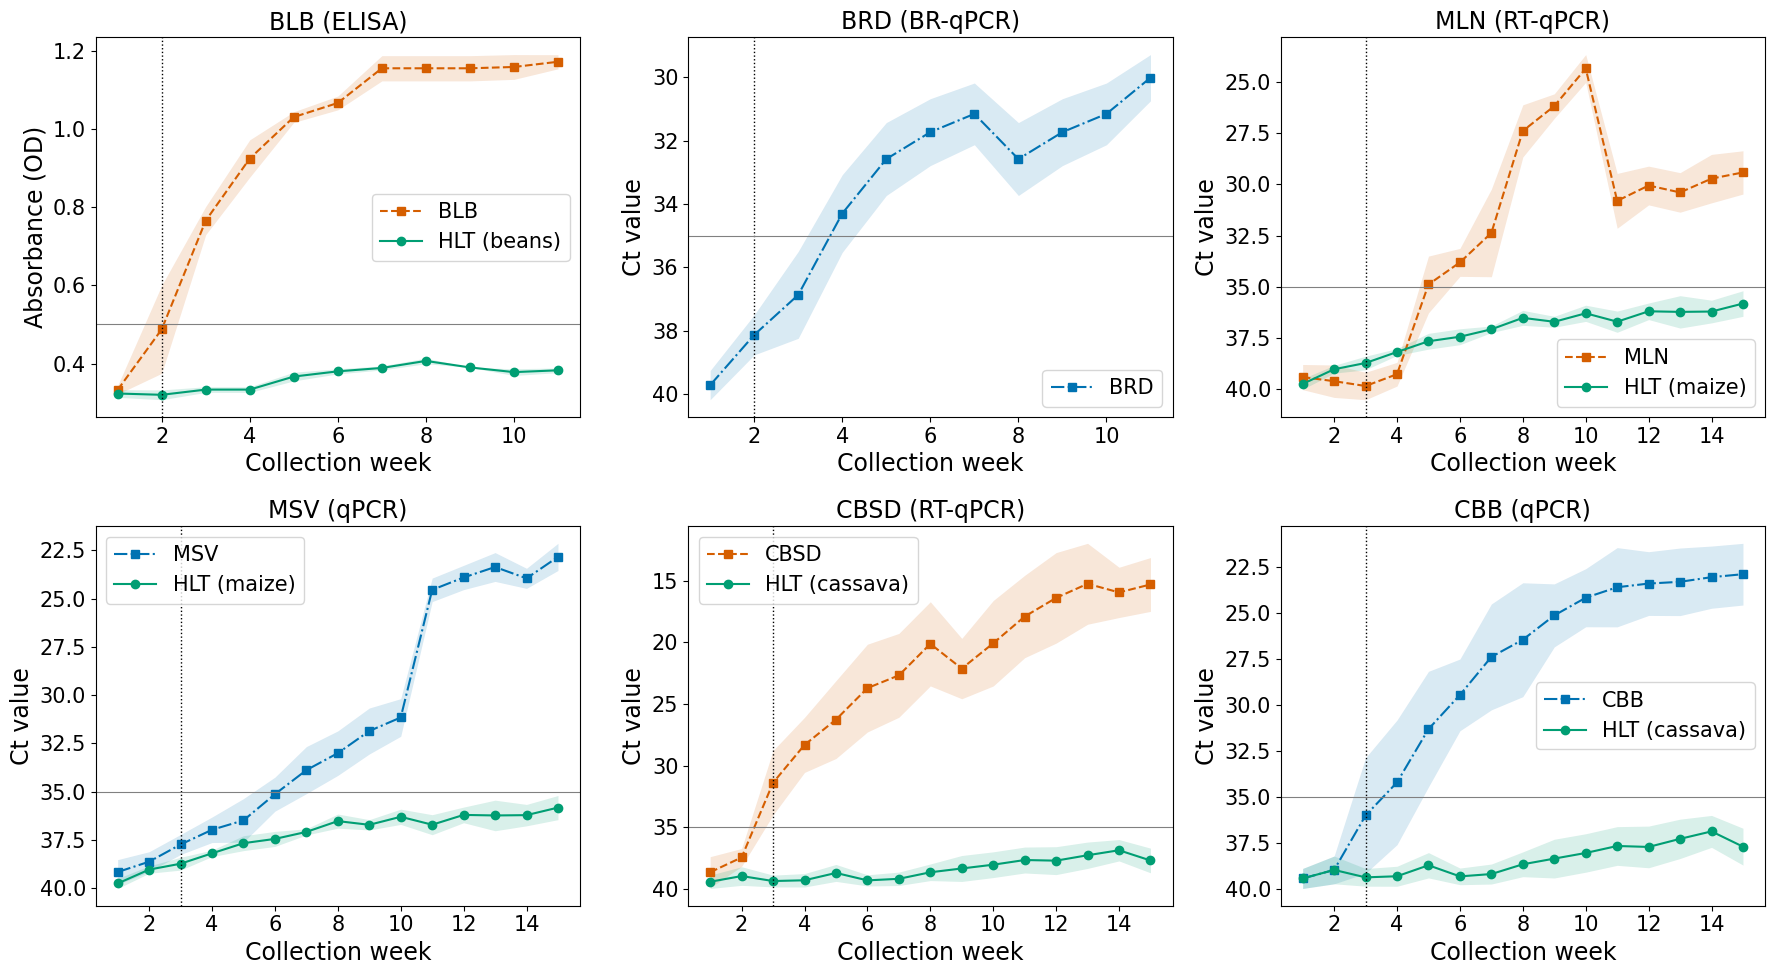

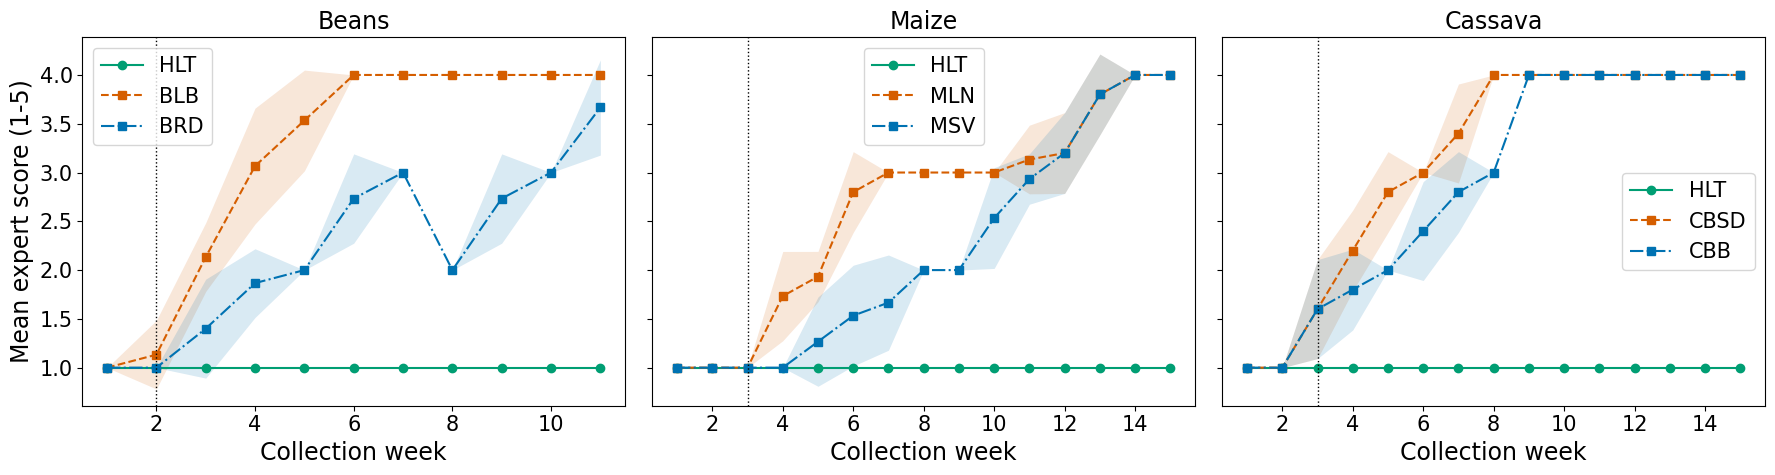

In [15]:
def weekly_stats(df, value):
    g = df.groupby('week')[value]
    return g.mean(), g.std()


def first_departure_week(dis, hlt, value, higher_is_more):
    # First week in which the disease-class mean lies beyond the healthy mean +/- 3 SD
    # (in the direction of more pathogen). Returns None if never, or if no healthy data.
    if hlt.empty:
        return None
    h_mean, h_sd = weekly_stats(hlt, value)
    d_mean, _ = weekly_stats(dis, value)
    for wk in sorted(d_mean.index):
        if wk not in h_mean.index or pd.isna(h_sd.get(wk)):
            continue
        thr = h_mean[wk] + 3 * h_sd[wk] if higher_is_more else h_mean[wk] - 3 * h_sd[wk]
        if (d_mean[wk] > thr) if higher_is_more else (d_mean[wk] < thr):
            return int(wk)
    return None


diseases = [('B', 'BLB'), ('B', 'BRD'), ('M', 'MLN'), ('M', 'MSV'), ('C', 'CBSD'), ('C', 'CBB')]
fig, ax = plt.subplots(2, 3, figsize=(18, 10))
summary = []
for axis, (crop, cls) in zip(ax.flatten(), diseases):
    assay = LAB_ASSAY[cls]
    unit = LAB_UNIT[assay]
    is_ct = 'Ct' in unit
    dis = lab_leaf[(lab_leaf['crop'] == crop) & (lab_leaf['class'] == cls)].dropna(subset=['lab_value'])
    hlt = lab_leaf[(lab_leaf['crop'] == crop) & (lab_leaf['class'] == 'HLT')].dropna(subset=['lab_value'])
    if HLT_UNIT.get(crop) != unit:
        hlt = hlt.iloc[0:0]                     # different assay/unit: not comparable
    for df, name, style in [(dis, cls, '-'), (hlt, f'HLT ({CROP_FULL_NAMES[crop].lower()})', '--')]:
        if df.empty:
            continue
        mean, sd = weekly_stats(df, 'lab_value')
        key = cls if name == cls else 'HLT'
        color = CLASS_COLOR_MAP[key]
        axis.plot(mean.index, mean.values, linestyle=CLASS_LINESTYLE[key], marker='o' if key == 'HLT' else 's', color=color, label=name)
        axis.fill_between(mean.index, mean - sd, mean + sd, color=color, alpha=0.15, linewidth=0)
    axis.axvline(INOCULATION_WEEK[crop], color='black', linestyle=':', linewidth=1)
    if lab_cutoff(crop, unit) is not None:
        axis.axhline(lab_cutoff(crop, unit), color='grey', linestyle='-', linewidth=0.8)
    if is_ct and INVERT_CT_AXIS:
        axis.invert_yaxis()
    axis.set_title(f'{cls} ({assay})')
    axis.set_xlabel('Collection week')
    axis.set_ylabel(unit)
    axis.xaxis.set_major_locator(MaxNLocator(integer=True))
    axis.legend(frameon=True, loc='best')

    scored = lab_leaf[(lab_leaf['crop'] == crop) & (lab_leaf['class'] == cls)].dropna(subset=['expert_score'])
    s_mean, _ = weekly_stats(scored, 'expert_score')
    visible = next((int(w) for w in sorted(s_mean.index) if s_mean[w] > 1), None)
    cut = lab_cutoff(crop, unit)
    lab_onset = None
    if cut is not None and not dis.empty:
        pos = (dis['lab_value'] < cut) if is_ct else (dis['lab_value'] > cut)
        share = pos.groupby(dis['week']).mean()
        lab_onset = next((int(w) for w in sorted(share.index) if share[w] >= 0.5), None)
    summary.append({'class': cls, 'assay': assay, 'inoculation_week': INOCULATION_WEEK[crop],
                    'lab_positive_week_(>=50%_leaves)': lab_onset,
                    'lab_departs_from_healthy_week': first_departure_week(dis, hlt, 'lab_value', not is_ct),
                    'mean_score_above_1_week': visible,
                    'healthy_comparison': not hlt.empty})
fig.tight_layout()
fig.savefig(OUT_DIR / 'ground_truth_lab_values.png', dpi=300)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for axis, crop in zip(ax, CROP_FULL_NAMES):
    for cls in CROP_CLASSES[crop]:
        df = lab_leaf[(lab_leaf['crop'] == crop) & (lab_leaf['class'] == cls)].dropna(subset=['expert_score'])
        if df.empty:
            continue
        mean, sd = weekly_stats(df, 'expert_score')
        axis.plot(mean.index, mean.values, marker='o' if cls == 'HLT' else 's', color=CLASS_COLOR_MAP[cls], label=cls,
                  linestyle=CLASS_LINESTYLE[cls])
        axis.fill_between(mean.index, mean - sd, mean + sd, color=CLASS_COLOR_MAP[cls], alpha=0.15, linewidth=0)
    axis.axvline(INOCULATION_WEEK[crop], color='black', linestyle=':', linewidth=1)
    axis.set_title(CROP_FULL_NAMES[crop])
    axis.set_xlabel('Collection week')
    axis.xaxis.set_major_locator(MaxNLocator(integer=True))
    axis.legend(frameon=True, loc='best')
ax[0].set_ylabel('Mean expert score (1-5)')
fig.tight_layout()
fig.savefig(OUT_DIR / 'ground_truth_expert_scores.png', dpi=300)
plt.show()

summary = pd.DataFrame(summary)
summary.to_csv(OUT_DIR / 'ground_truth_summary.csv', index=False)

## 9. Measurement repeatability

Compares the two measurement points on the same leaf in the same week (within-leaf), and uses leaves from different plants of the same class and week as a reference (between-plant). If the instrument is repeatable, within-leaf differences should be smaller than between-plant differences. Retakes at the same point are averaged first. Same preprocessing as Figure 2.

In [16]:
def leaf_point_spectra(device):
    x, meta, wl = prepared_spectra(device)
    keys = ['crop', 'class', 'week', 'plant', 'leaf']
    df = pd.concat([meta[keys + ['point']].reset_index(drop=True), pd.DataFrame(x)], axis=1)
    spec_cols = list(range(x.shape[1]))
    return df.groupby(keys + ['point'])[spec_cols].mean(), keys


def pair_stats(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    return np.corrcoef(a, b)[0, 1], np.mean(np.abs(a - b))


rng = np.random.default_rng(42)
rows = []
for device in Device.get_devices():
    by_point, keys = leaf_point_spectra(device)
    within_r, within_d, between_r, between_d = [], [], [], []
    leaf_means = {}
    for key, g in by_point.groupby(level=keys):
        arr = g.values
        if len(arr) == 2:
            r, d = pair_stats(arr[0], arr[1])
            within_r.append(r); within_d.append(d)
        leaf_means[key] = np.nanmean(arr, axis=0)
    # between-plant reference: leaves of different plants, same crop/class/week/leaf position
    groups = {}
    for (crop, cls, week, plant, leaf), spec in leaf_means.items():
        groups.setdefault((crop, cls, week, leaf), []).append(spec)
    for specs in groups.values():
        for i in range(len(specs)):
            for j in range(i + 1, len(specs)):
                r, d = pair_stats(specs[i], specs[j])
                between_r.append(r); between_d.append(d)
    unit = 'normalized intensity' if device == Device.LOW_COST else 'reflectance (fraction)'
    rows.append({'device': DEVICE_DISPLAY_NAMES[device], 'leaf_pairs': len(within_r),
                 'within_leaf_median_r': np.nanmedian(within_r),
                 'between_plant_median_r': np.nanmedian(between_r),
                 'within_leaf_median_abs_diff': np.nanmedian(within_d),
                 'between_plant_median_abs_diff': np.nanmedian(between_d),
                 'unit_of_diff': unit})
repeat = pd.DataFrame(rows)
repeat.to_csv(OUT_DIR / 'repeatability.csv', index=False)
print(repeat.round(3).to_string(index=False))
print("\nr = Pearson correlation between the two spectra (shape agreement); "
      "abs_diff = mean absolute difference across bands (magnitude agreement).")

    device  leaf_pairs  within_leaf_median_r  between_plant_median_r  within_leaf_median_abs_diff  between_plant_median_abs_diff           unit_of_diff
    CI-710        1870                 0.996                   0.995                        0.021                          0.027 reflectance (fraction)
ScanCorder        1779                 0.997                   0.995                        0.014                          0.022 reflectance (fraction)
  Low-Cost        1845                 0.928                   0.860                        0.091                          0.142   normalized intensity

r = Pearson correlation between the two spectra (shape agreement); abs_diff = mean absolute difference across bands (magnitude agreement).


In [17]:
rows = []
for f in sorted(DATA_ROOT.rglob('*.csv')):
    if 'Scancorder' not in f.parts:
        continue
    df = pd.read_csv(f)
    dup = df[df.duplicated(subset=['UUID'], keep=False)]
    if len(dup):
        rows.append(dup.assign(file=f.name))
dups = pd.concat(rows) if rows else pd.DataFrame()
print(f"Rows sharing a UUID: {len(dups)}")
if len(dups):
    dups['class'] = dups['Sample ID'].str.split().str[1].str.replace(r'\d+$', '', regex=True)
    print(dups.groupby(['file', 'class']).size().rename('rows').to_string())
    dups[['file', 'Sample ID', 'UUID', 'Timestamp']].to_csv(OUT_DIR / 'scancorder_duplicate_uuids.csv', index=False)

Rows sharing a UUID: 0


In [18]:
loaded = set()
for fl in global_state[Device.BIO_SCIENCE]['ds'].final_df['Files']:
    for f in (fl if isinstance(fl, (list, tuple)) else [fl]):
        loaded.add(pathlib.Path(f).resolve())
all_files = [f for f in DATA_ROOT.rglob('*.csv')
             if 'Spectrometer' in f.parts and '_calculations' not in f.stem]
skipped = sorted(f for f in all_files if f.resolve() not in loaded)
print(f"CI-710 spectrum files: {len(all_files)}, loaded: {len(loaded)}, skipped: {len(skipped)}")
for f in skipped:
    print(f.relative_to(DATA_ROOT))

CI-710 spectrum files: 3783, loaded: 3783, skipped: 0


In [19]:
ds = global_state[Device.BIO_SCIENCE]['ds']
multi = ds.final_df[ds.final_df['Files'].apply(lambda fl: isinstance(fl, (list, tuple)) and len(fl) > 1)]
print(f"Readings backed by more than one file: {len(multi)}  "
      f"(extra files dropped: {int(multi['Files'].apply(len).sum() - len(multi))})")
for _, r in multi.iterrows():
    print(f"week {r['Week']}  {r['Label']}  {r['R']}:")
    for f in r['Files']:
        print("    ", pathlib.Path(f).relative_to(DATA_ROOT))

Readings backed by more than one file: 0  (extra files dropped: 0)


In [23]:
import shutil, pathlib
for f in pathlib.Path('spectra_data').rglob('.ipynb_checkpoints'):
    shutil.rmtree(f)
    print('Deleted', f)

In [24]:
import shutil, pathlib
folders = list(pathlib.Path('spectra_data').rglob('.ipynb_checkpoints'))
for f in folders:
    shutil.rmtree(f)
print(f"Deleted {len(folders)} checkpoint folders")

Deleted 0 checkpoint folders
